In [125]:
import pandas as pd
import numpy as np

In [126]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [127]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix

In [128]:
training_path = "../datasets/training_dataset.csv"
validation_path = "../datasets/validation_dataset.csv"

In [129]:
training_dataset = pd.read_csv(training_path)
validation_dataset = pd.read_csv(validation_path)

In [130]:
training_dataset.shape

(7000, 12)

In [131]:
x_train = training_dataset.iloc[:, :11]
y_train =  training_dataset.iloc[:, 11]

In [132]:
x_val = validation_dataset.iloc[:, :11]
y_val = validation_dataset.iloc[:, 11]

decision tree model

In [133]:
def metrics(y_test, pred):
    metrics = {}
    metrics["accuracy_score"] = accuracy_score(y_test, pred)
    metrics["precision_score"] = precision_score(y_test, pred)
    metrics["recall_score"] = recall_score(y_test, pred)
    metrics["f1_score"] = f1_score(y_test, pred)
    metrics["roc_auc_score"] = roc_auc_score(y_test, pred)
    metrics["confusion_matrix"] = confusion_matrix(y_test, pred)

    return metrics

In [134]:
report = {}

In [135]:
model1 = DecisionTreeClassifier(max_depth = 10)
model1.fit(x_train, y_train)
predict = model1.predict(x_val)
report["Decision_tree"] = metrics(y_val, predict)

In [136]:
model2 = RandomForestClassifier(max_depth=10)
model2.fit(x_train, y_train)
predict = model2.predict(x_val)
report["Random_Forest"] = metrics(y_val, predict)

In [137]:
model3 = SVC()
model3.fit(x_train, y_train)
predict = model3.predict(x_val)
report["SVC"] = metrics(y_val, predict)

In [138]:
model4 = KNeighborsClassifier()
model4.fit(x_train, y_train)
predict = model4.predict(x_val)
report["KNN"] = metrics(y_val, predict)

In [139]:
report["Decision_tree"]

{'accuracy_score': 0.836,
 'precision_score': 0.5855855855855856,
 'recall_score': 0.45774647887323944,
 'f1_score': 0.5138339920948617,
 'roc_auc_score': 0.6910442920681986,
 'confusion_matrix': array([[1124,   92],
        [ 154,  130]])}

In [140]:
report["Random_Forest"]

{'accuracy_score': 0.8766666666666667,
 'precision_score': 0.8152866242038217,
 'recall_score': 0.4507042253521127,
 'f1_score': 0.5804988662131519,
 'roc_auc_score': 0.7134277705707932,
 'confusion_matrix': array([[1187,   29],
        [ 156,  128]])}

In [141]:
report["KNN"]

{'accuracy_score': 0.8446666666666667,
 'precision_score': 0.625615763546798,
 'recall_score': 0.4471830985915493,
 'f1_score': 0.5215605749486653,
 'roc_auc_score': 0.6923415492957746,
 'confusion_matrix': array([[1140,   76],
        [ 157,  127]])}

In [142]:
report["SVC"]

{'accuracy_score': 0.8686666666666667,
 'precision_score': 0.8041958041958042,
 'recall_score': 0.40492957746478875,
 'f1_score': 0.5386416861826698,
 'roc_auc_score': 0.6909516308376575,
 'confusion_matrix': array([[1188,   28],
        [ 169,  115]])}

DecisionTree is our best bet, we will do hyperparameter finetunning for the same, since we are more focused on recall which indicates churn amount predicted correctly

In [170]:
second_iter_model = DecisionTreeClassifier(max_depth = 10)
second_iter_model.fit(x_train, y_train)
pred = second_iter_model.predict_proba(x_val)[:, 1]
pred = (pred >= 0.19).astype(int)
metrics(y_val, pred)

{'accuracy_score': 0.7713333333333333,
 'precision_score': 0.432183908045977,
 'recall_score': 0.6619718309859155,
 'f1_score': 0.5229485396383866,
 'roc_auc_score': 0.7294234154929577,
 'confusion_matrix': array([[969, 247],
        [ 96, 188]])}

In [ ]:
from xgboost import XGBClassifier

model = XGBClassifier()
model.fit(x_train, y_train)
predict = model.predict(x_val)
report["xgboost"] = metrics(y_val, predict)

In [ ]:
report["xgboost"]

{'accuracy_score': 0.8533333333333334,
 'precision_score': 0.6632653061224489,
 'recall_score': 0.45774647887323944,
 'f1_score': 0.5416666666666666,
 'roc_auc_score': 0.7017350815418829,
 'confusion_matrix': array([[1150,   66],
        [ 154,  130]])}

In [ ]:
params = {
    'max_depth' : [3,4,5,6],
    'learning_rate' : [0.01, 0.03, 0.05,0.1],
    'n_estimators' : [200,300,400],
}

clf = GridSearchCV(model, param_grid=params)
clf.fit(x_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.01, 0.03, ...], 'max_depth': [3, 4, ...], 'n_estimators': [200, 300, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is display

In [169]:
xgboost_final_model = XGBClassifier(max_depth = 7, learning_rate = 0.01,n_estimators = 1000)
xgboost_final_model.fit(x_train, y_train)
predict = xgboost_final_model.predict_proba(x_val)[:, 1]
predict = (predict >= 0.2).astype(int)
report["xgboost"] = metrics(y_val, predict)
report["xgboost"]

{'accuracy_score': 0.8053333333333333,
 'precision_score': 0.49099099099099097,
 'recall_score': 0.7676056338028169,
 'f1_score': 0.5989010989010989,
 'roc_auc_score': 0.7908751853224611,
 'confusion_matrix': array([[990, 226],
        [ 66, 218]])}

In [172]:
testing_dataset = pd.read_csv("../datasets/testing_dataset.csv")

In [173]:
x_test = testing_dataset.iloc[:, :11]
y_test =  testing_dataset.iloc[:, 11]

In [180]:
predict_prob = xgboost_final_model.predict_proba(x_test)[:, 1]
predict = (predict >= 0.19).astype(int)
metrics(y_test, predict)

{'accuracy_score': 0.7933333333333333,
 'precision_score': 0.4892241379310345,
 'recall_score': 0.7566666666666667,
 'f1_score': 0.5942408376963351,
 'roc_auc_score': 0.7795833333333334,
 'confusion_matrix': array([[963, 237],
        [ 73, 227]])}

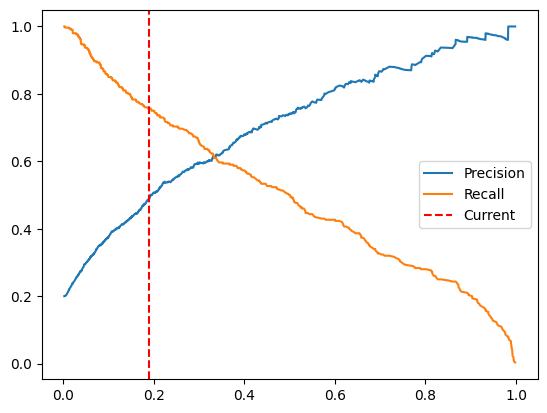

In [182]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(y_test, predict_prob)
plt.plot(thresholds, precision[:-1], label='Precision')
plt.plot(thresholds, recall[:-1], label='Recall')
plt.axvline(0.19, color='red', linestyle='--', label='Current')
plt.legend()
plt.show()

In [185]:
import pickle

f = open("model.pkl", "wb")
pickle.dump(xgboost_final_model, f)
f.close()